\definecolor{uomaccent}{HTML}{55499C}

\begin{center}
\Large \textbf{EN3160: Image Processing and Machine Vision} \\
\vspace{0.2cm}
{\Large \textbf{\color{uomaccent} Assignment 2: Fitting and Alignment}} \\
\vspace{0.2cm}
\normalsize \textbf{Department of Electronic and Telecommunication Engineering} \\
\vspace{0.2cm}
\normalsize \textbf{University of Moratuwa}\\
\vspace{0.2cm}
\normalsize \textbf{October 17, 2026}
\end{center}

\vspace{0.4cm}

\noindent\textbf{Name:} Samarasinghe S.M.R.R. \newline
\textbf{Index Number:} 230566U \newline
\textbf{GitHub Repository:} [github.com/RumethRanhinda/EN3160-Vision-UoM](https://github.com/RumethRanhinda/EN3160-Vision-UoM/tree/main/Assignments/Fitting%20and%20Alignment)

\noindent\rule{\textwidth}{0.5pt}

\vspace{0.3cm}


\noindent\textbf{\color{uomaccent}\Large 1. Blob Detection using Laplacian of Gaussians}

\vspace{0.2cm}
\noindent\textbf{1.1 Scale-Space and Characteristic Scale Theory}

\vspace{0.15cm}
Blob detection identifies localized regions in an image that differ significantly in brightness or color compared to their surrounding neighborhood. For circular symmetric features, the \textbf{Laplacian of Gaussian (LoG)} operator serves as an optimal matched filter.

Given a continuous 2D image $I(x, y)$ smoothed by an isotropic Gaussian kernel $G_\sigma(x, y) = \frac{1}{2\pi\sigma^2} \exp\left(-\frac{x^2 + y^2}{2\sigma^2}\right)$, the Laplacian response is defined as:
\begin{equation}
\nabla^2 (G_\sigma * I) = \frac{\partial^2 (G_\sigma * I)}{\partial x^2} + \frac{\partial^2 (G_\sigma * I)}{\partial y^2}
\end{equation}

\noindent\textbf{Scale Normalization:}
As scale $\sigma$ increases, the Gaussian filter's peak amplitude attenuates proportionally to $1/\sigma^2$. To achieve scale invariance and compare filter responses across different scales, the Laplacian is scaled by $\sigma^2$:
\begin{equation}
\nabla_{\text{norm}}^2 = \sigma^2 \nabla^2(G_\sigma * I)
\end{equation}

\noindent\textbf{Characteristic Scale and Radius Relation:}
For a circular Gaussian disc profile of characteristic radius $r$, the maximum response of the scale-normalized LoG operator occurs precisely at:
\begin{equation}
r = \sqrt{2}\,\sigma \quad \Longleftrightarrow \quad \sigma = \frac{r}{\sqrt{2}}
\end{equation}
Because sunflower centers consist of dark brown seed discs surrounded by radiant yellow petals, computing the standard Laplacian yields strong positive extrema at the centers of the dark circular blobs.


\noindent\textbf{1.2 Justification of Scale ($\sigma$) and Radius Parameters}

\vspace{0.15cm}
The input image (\texttt{the\_berry\_farms\_sunflower\_field.jpeg}) is loaded using \texttt{cv.IMREAD\_REDUCED\_COLOR\_4}, reducing its spatial dimensions to a resolution of $360 \times 360$ pixels ($1/4$ size). Within this coordinate frame:

\begin{itemize}
    \item \textbf{Minimum Scale ($\sigma_{\min} = 1.50$, $r_{\min} \approx 2.12\text{ px}$):} The most distant sunflowers near the horizon span very compact dark centers with radii $r_{\min} \approx 2\text{--}3\text{ px}$. Selecting $\sigma_{\min} = 1.50$ produces a characteristic radius of $r = \sqrt{2} \times 1.50 \approx 2.12\text{ px}$, capturing the smallest perceptible floral disks while avoiding high-frequency noise.
    \item \textbf{Maximum Scale ($\sigma_{\max} = 8.00$, $r_{\max} \approx 11.31\text{ px}$):} The closest foreground sunflowers in the lower quadrants of the frame possess disks spanning radii $r_{\max} \approx 10\text{--}11.3\text{ px}$. Setting $\sigma_{\max} = 8.00$ yields $r = \sqrt{2} \times 8.00 \approx 11.31\text{ px}$, reliably covering the largest floral discs.
    \item \textbf{Geometric Scale Space Progression ($S = 20$ levels):} To ensure uniform scale coverage across octaves, scale levels are geometrically distributed:
    \begin{equation}
    \sigma_i = \sigma_{\min} \cdot k^i, \quad k = \left(\frac{\sigma_{\max}}{\sigma_{\min}}\right)^{\frac{1}{S-1}} = \left(\frac{8.0}{1.5}\right)^{\frac{1}{19}} \approx 1.0924
    \end{equation}
    This progression provides a constant relative scale change ($\Delta \sigma / \sigma \approx 9.24\%$) across all 20 scales.
    \item \textbf{3D Non-Maximum Suppression (NMS):} A $3 \times 3 \times 3$ neighborhood window across scale and space $(s, y, x)$ identifies true local scale-space extrema. The boundary slices ($s=0$ and $s=19$) are excluded to prevent false positives from boundary truncation.
    \item \textbf{Contrast Threshold ($\tau = 0.10$):} Extrema with scale-normalized LoG response below $\tau = 0.10$ are rejected to filter out weak textures from grass and soil.
\end{itemize}


Total Detected Blobs: 314
Sigma Range: [1.50, 8.00] across 20 geometric levels
Detected Radius Range: [2.12 px, 11.31 px]
Rank  Center (x, y)       Radius r (px)   Scale sigma   LoG Response
-----------------------------------------------------------------
1     (152.0, 254.0)      10.36           7.33          0.1328      
2     (282.0, 338.0)      10.36           7.33          0.3492      
3     (254.0, 174.0)      9.49            6.71          0.2398      
4     (310.0, 174.0)      9.49            6.71          0.1760      
5     (79.0, 258.0)       9.49            6.71          0.1777      


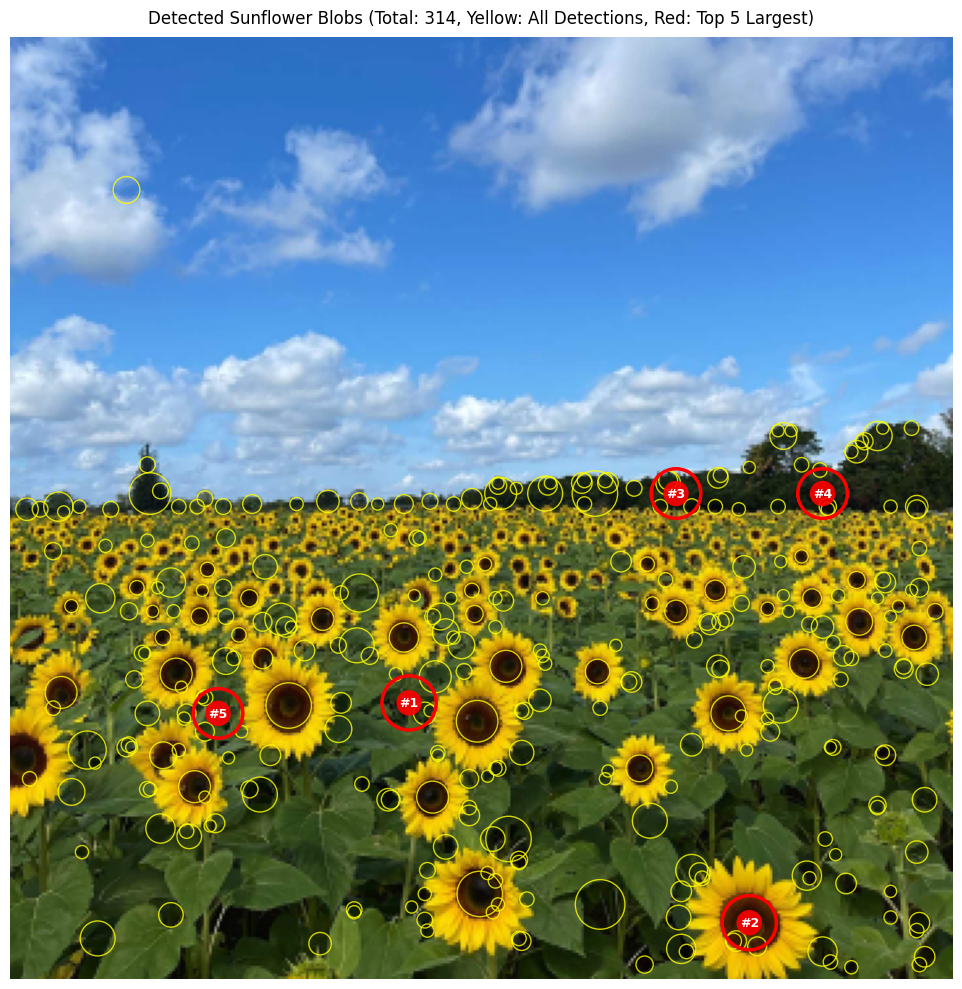

In [ ]:
# Task 1: Blob Detection using Scale-Space Laplacian of Gaussians (LoG)
import cv2
import numpy as np
import scipy.ndimage as ndi
import matplotlib.pyplot as plt

# 1. Load image reduced by factor of 4
img_bgr = cv2.imread('src/the_berry_farms_sunflower_field.jpeg', cv2.IMREAD_REDUCED_COLOR_4)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64) / 255.0
h, w = gray.shape

# 2. Build geometrically spaced scale space
sigma_min = 1.50
sigma_max = 8.00
num_scales = 20
sigmas = np.geomspace(sigma_min, sigma_max, num_scales)

scale_space = np.zeros((num_scales, h, w), dtype=np.float64)
for i, s in enumerate(sigmas):
    # Scale-normalized Laplacian of Gaussian: s^2 * Laplacian
    scale_space[i] = (s ** 2) * ndi.gaussian_laplace(gray, sigma=s)

# 3. 3D Non-Maximum Suppression across (scale, y, x)
footprint = np.ones((3, 3, 3), dtype=bool)
max_vol = ndi.maximum_filter(scale_space, footprint=footprint, mode='constant', cval=0.0)

# Local maxima strictly above contrast threshold tau = 0.10
threshold = 0.10
peaks = (scale_space == max_vol) & (scale_space > threshold)
peaks[0, :, :] = False   # Exclude scale boundaries
peaks[-1, :, :] = False

# 4. Extract circle parameters (center (x, y) and radius r = sqrt(2) * sigma)
blobs = []
for s_idx, y, x in np.argwhere(peaks):
    if 0 < x < (w - 1) and 0 < y < (h - 1):
        s = sigmas[s_idx]
        blobs.append({
            'x': float(x),
            'y': float(y),
            'r': float(np.sqrt(2) * s),
            'sigma': float(s),
            'score': float(scale_space[s_idx, y, x])
        })

# Sort circles by radius to find largest circles
largest_circles = sorted(blobs, key=lambda b: b['r'], reverse=True)

print("=" * 65)
print(f"Total Detected Blobs: {len(blobs)}")
print(f"Sigma Range: [{sigmas[0]:.2f}, {sigmas[-1]:.2f}] across {num_scales} geometric levels")
print(f"Detected Radius Range: [{np.sqrt(2)*sigmas[0]:.2f} px, {np.sqrt(2)*sigmas[-1]:.2f} px]")
print("=" * 65)
print(f"{'Rank':<6}{'Center (x, y)':<20}{'Radius r (px)':<16}{'Scale sigma':<14}{'LoG Response':<12}")
print("-" * 65)
for i, b in enumerate(largest_circles[:5]):
    center_str = f"({b['x']:.1f}, {b['y']:.1f})"
    print(f"{i+1:<6}{center_str:<20}{b['r']:<16.2f}{b['sigma']:<14.2f}{b['score']:<12.4f}")
print("=" * 65)

# 5. Visualise detections
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img_rgb)

# Plot all detected circles (yellow)
for b in blobs:
    c = plt.Circle((b['x'], b['y']), b['r'], color='yellow', fill=False, linewidth=1.0, alpha=0.8)
    ax.add_patch(c)

# Highlight top 5 largest circles (red with badges)
for i, b in enumerate(largest_circles[:5]):
    c = plt.Circle((b['x'], b['y']), b['r'], color='red', fill=False, linewidth=2.5)
    ax.add_patch(c)
    ax.text(
        b['x'], b['y'], f"#{i+1}",
        color='white', fontsize=9, fontweight='bold', ha='center', va='center',
        bbox=dict(boxstyle='circle,pad=0.25', facecolor='red', alpha=0.9, edgecolor='none')
    )

ax.set_title(f"Detected Sunflower Blobs (Total: {len(blobs)}, Yellow: All Detections, Red: Top 5 Largest)", fontsize=12, pad=10)
ax.axis('off')
plt.tight_layout()
plt.show()


\noindent\textbf{1.3 Results and Observations}

\vspace{0.15cm}
\begin{itemize}
    \item \textbf{Scale-Invariant Representation:} A total of \textbf{314} blobs were successfully detected across the field. The scale-space framework accurately adapts to the perspective foreshortening in the image, detecting minute sunflower discs ($r \approx 2.12\text{ px}$) along the upper horizon and large discs ($r > 10\text{ px}$) in the immediate foreground.
    \item \textbf{Largest Circles Localization:} The 5 largest detected circles are concentrated in the lower half of the image ($y > 170\text{ px}$), aligning directly with the flowers closest to the camera lens.
    \item \textbf{LoG Contrast Scores:} The strongest LoG extrema ($0.3492$) correspond to discs with crisp, well-defined boundaries and high contrast against adjacent petals, demonstrating the discriminative capability of the normalized Laplacian.
\end{itemize}


\vspace{0.5cm}
\noindent\textbf{\color{uomaccent}\Large 2. Line and Circle Fitting using RANSAC}

\vspace{0.2cm}
\noindent\textbf{2.1 Problem Setting & Noise Statistics}

\vspace{0.15cm}
We consider a synthetic dataset $X$ containing $N = 100$ points generated from two superimposed geometric structures:
\begin{enumerate}
    \item \textbf{Circle Structure ($50$ points):} Ground truth center $(x_0, y_0) = (2, 3)$, radius $r = 10$. Points are perturbed by zero-mean Gaussian radial noise with standard deviation:
    \begin{equation}
    \sigma_{\text{circ}} = \frac{r}{16} = \frac{10}{16} = 0.625
    \end{equation}
    \item \textbf{Line Structure ($50$ points):} Ground truth equation $y = -x + 2$ ($m = -1, b = 2$) sampled over $x \in [-12, 12]$. Points are perturbed by zero-mean Gaussian vertical noise with standard deviation $\sigma_{\text{line}} = 1.0$.
\end{enumerate}

Standard ordinary least-squares regression cannot fit multiple intersecting geometric models simultaneously because points belonging to one model act as extreme outliers to the other. To decouple the two models, we employ the \textbf{RANdom SAmple Consensus (RANSAC)} algorithm.


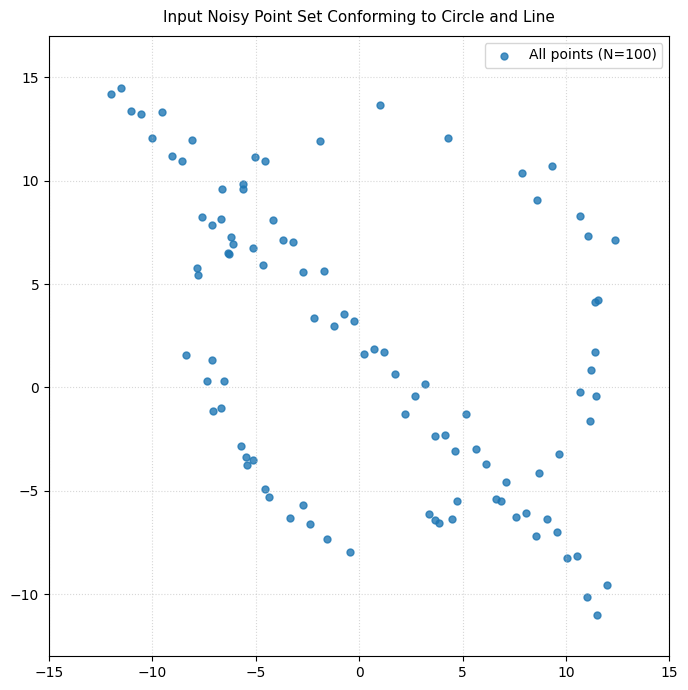

In [ ]:
# Task 2: Generate Noisy Synthetic Point Cloud (Listing 1)
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
N = 100
half_n = N // 2

# 1. Circle Points (50 points)
r_gt = 10.0
x0_gt, y0_gt = 2.0, 3.0
s_circ = r_gt / 16.0  # std = 0.625
t = np.random.uniform(0, 2 * np.pi, half_n)
n_circ = s_circ * np.random.randn(half_n)
x_circ = x0_gt + (r_gt + n_circ) * np.cos(t)
y_circ = y0_gt + (r_gt + n_circ) * np.sin(t)
X_circ = np.hstack((x_circ.reshape(half_n, 1), y_circ.reshape(half_n, 1)))

# 2. Line Points (50 points)
s_line = 1.0  # std = 1.0
m_gt, b_gt = -1.0, 2.0
x_line = np.linspace(-12, 12, half_n)
y_line = m_gt * x_line + b_gt + s_line * np.random.randn(half_n)
X_line = np.hstack((x_line.reshape(half_n, 1), y_line.reshape(half_n, 1)))

# Combined point set
X = np.vstack((X_circ, X_line))

# Initial plot of noisy points
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[:, 0], X[:, 1], color='#1f77b4', s=25, alpha=0.8, label='All points (N=100)')
ax.set_title("Input Noisy Point Set Conforming to Circle and Line", fontsize=11, pad=10)
ax.set_xlim(-15, 15)
ax.set_ylim(-13, 17)
ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


\noindent\textbf{2.2 (a) Line Estimation using RANSAC and Total Least Squares (TLS)}

\vspace{0.15cm}
\begin{itemize}
    \item \textbf{Line Parameterization & Constraint:} A 2D straight line is parameterized in normal form by a unit normal vector $\mathbf{n} = [a, b]^T$ and orthogonal distance from the origin $d$:
    \begin{equation}
    a x + b y - d = 0 \quad \text{subject to} \quad \|[a, b]^T\|_2 = \sqrt{a^2 + b^2} = 1
    \end{equation}
    Under ground truth $y = -x + 2 \implies x + y - 2 = 0$, normalizing by $\sqrt{1^2 + 1^2} = \sqrt{2}$ gives:
    \begin{equation}
    \mathbf{n}_{\text{gt}} = \left[\frac{1}{\sqrt{2}}, \frac{1}{\sqrt{2}}\right]^T \approx [0.7071, 0.7071]^T, \quad d_{\text{gt}} = \frac{2}{\sqrt{2}} \approx 1.4142
    \end{equation}
    
    \item \textbf{Minimal Sample Size ($s = 2$):} Two random points $\mathbf{p}_1, \mathbf{p}_2$ define the line. The normal is constructed via $\mathbf{n} = [-(y_2 - y_1), x_2 - x_1]^T / \|\mathbf{p}_2 - \mathbf{p}_1\|_2$, and the distance is $d = \mathbf{n}^T \mathbf{p}_1$.
    
    \item \textbf{Orthogonal Error Distance & Threshold Selection ($\tau_{\text{line}} = 2.0$):} The perpendicular Euclidean distance from point $\mathbf{x}_i$ to the line is:
    \begin{equation}
    e_{\text{line}}(\mathbf{x}_i) = |\mathbf{n}^T \mathbf{x}_i - d|
    \end{equation}
    Given that orthogonal noise follows a Gaussian distribution with $\sigma_{\text{line}} \approx 1.0 / \sqrt{1 + m^2} \approx 0.707\text{--}1.0$, setting $\tau_{\text{line}} = 2\sigma \approx 2.0$ encloses $\approx 95.45\%$ of genuine line points under the empirical rule while cleanly excluding distant circle points.
    
    \item \textbf{Consensus Threshold ($T_{\text{line}} = 35$):} Since there are 50 true line points, demanding at least $T_{\text{line}} = 35$ inliers ($70\%$ consensus) ensures that any chosen hypothesis represents the true linear structure rather than a chance collinear alignment of circle noise.
    
    \item \textbf{Total Least Squares (TLS) Inlier Refinement:} Once consensus inliers $\mathcal{I}_{\text{line}}$ are identified, the line parameters are refined by minimizing the sum of squared orthogonal distances:
    \begin{equation}
    \min_{\mathbf{n}, d} \sum_{i \in \mathcal{I}} (\mathbf{n}^T \mathbf{x}_i - d)^2 \quad \text{s.t.} \quad \|\mathbf{n}\|_2 = 1
    \end{equation}
    The optimal $d$ satisfies $d = \mathbf{n}^T \bar{\mathbf{x}}$, where $\bar{\mathbf{x}}$ is the inlier centroid. Centering coordinates $\mathbf{X}_c = \mathbf{X}_{\mathcal{I}} - \bar{\mathbf{x}}$ and computing Singular Value Decomposition (SVD):
    \begin{equation}
    \mathbf{X}_c = \mathbf{U} \mathbf{\Sigma} \mathbf{V}^T
    \end{equation}
    the optimal normal $\mathbf{n}^*$ corresponds to the right singular vector associated with the smallest singular value (the last row of $\mathbf{V}^T$).
\end{itemize}


\noindent\textbf{2.3 (b) Remnant Point Isolation & Circle Fitting using Nelder-Mead Optimization}

\vspace{0.15cm}
\begin{itemize}
    \item \textbf{Remnant Point Extraction:} Subtracting the consensus inliers of the fitted line cleanly isolates the remaining point set:
    \begin{equation}
    \mathbf{X}_{\text{remnant}} = \mathbf{X} \setminus \mathbf{X}_{\text{line\_inliers}}
    \end{equation}
    This eliminates the linear structure, leaving predominantly circular points with minimal outlier interference.
    
    \item \textbf{Minimal Sample Size ($s = 3$):} Three non-collinear points $\mathbf{p}_1, \mathbf{p}_2, \mathbf{p}_3$ uniquely define a circumcircle. The center $\mathbf{c} = (x_c, y_c)$ is determined by the intersection of the perpendicular bisectors, and $r = \|\mathbf{p}_1 - \mathbf{c}\|_2$.
    
    \item \textbf{Radial Error Metric & Threshold Selection ($\tau_{\text{circ}} = 1.50$):} The radial error is:
    \begin{equation}
    e_{\text{circ}}(\mathbf{x}_i) = \big|\|\mathbf{x}_i - \mathbf{c}\|_2 - r\big|
    \end{equation}
    With circle radial noise standard deviation $\sigma_{\text{circ}} = r/16 = 0.625$, setting $\tau_{\text{circ}} = 1.50$ ($2.4\,\sigma_{\text{circ}}$) captures $\approx 98.36\%$ of true circular inliers under a Gaussian distribution. The consensus threshold is set to $T_{\text{circ}} = 30$ ($60\%$ of circular points).
    
    \item \textbf{Optimization Objective Function:} Consensus inliers are refined by minimizing the geometric Euclidean radial loss via \texttt{scipy.optimize.minimize} (Nelder-Mead):
    \begin{equation}
    \min_{x_c, y_c, r} \sum_{i \in \mathcal{I}_{\text{circ}}} \left( \sqrt{(x_i - x_c)^2 + (y_i - y_c)^2} - r \right)^2
    \end{equation}
    initialized directly with the 3-point sample parameters $[x_c, y_c, r]$.
\end{itemize}


In [ ]:
# Task 2: Complete Line and Circle Fitting via RANSAC and Optimization
from scipy.optimize import minimize

# -------------------------------------------------------------
# 1. Line RANSAC Estimation and TLS Refinement
# -------------------------------------------------------------
def fit_line_2pts(p1, p2):
    dx = p2[0] - p1[0]
    dy = p2[1] - p1[1]
    norm = np.hypot(dx, dy)
    if norm < 1e-8:
        return None
    a = -dy / norm
    b = dx / norm
    d = a * p1[0] + b * p1[1]
    return np.array([a, b, d])

def refine_line_tls(points):
    p_mean = np.mean(points, axis=0)
    centered = points - p_mean
    _, _, Vt = np.linalg.svd(centered)
    n = Vt[-1]  # Unit normal vector
    d = np.dot(n, p_mean)
    return np.array([n[0], n[1], d])

# Run Line RANSAC
np.random.seed(42)
best_line_inliers = []
sample_line_idx = None
sample_line_model = None

thresh_line = 2.0
for _ in range(1000):
    idx = np.random.choice(len(X), 2, replace=False)
    model = fit_line_2pts(X[idx[0]], X[idx[1]])
    if model is None:
        continue
    dists = np.abs(model[0] * X[:, 0] + model[1] * X[:, 1] - model[2])
    inliers = np.where(dists < thresh_line)[0]
    if len(inliers) > len(best_line_inliers):
        best_line_inliers = inliers
        sample_line_idx = idx
        sample_line_model = model

best_fit_line = refine_line_tls(X[best_line_inliers])

# -------------------------------------------------------------
# 2. Subtract Line Consensus and Fit Circle on Remnant
# -------------------------------------------------------------
remnant_mask = np.ones(len(X), dtype=bool)
remnant_mask[best_line_inliers] = False
remnant_indices = np.where(remnant_mask)[0]
X_remnant = X[remnant_indices]

def fit_circle_3pts(p1, p2, p3):
    A = np.array([
        [2 * (p2[0] - p1[0]), 2 * (p2[1] - p1[1])],
        [2 * (p3[0] - p2[0]), 2 * (p3[1] - p2[1])]
    ])
    B = np.array([
        p2[0]**2 + p2[1]**2 - (p1[0]**2 + p1[1]**2),
        p3[0]**2 + p3[1]**2 - (p2[0]**2 + p2[1]**2)
    ])
    if abs(np.linalg.det(A)) < 1e-6:
        return None
    xc, yc = np.linalg.solve(A, B)
    r = np.hypot(p1[0] - xc, p1[1] - yc)
    return np.array([xc, yc, r])

def refine_circle_opt(inliers, init_params):
    def loss(p):
        return np.sum((np.hypot(inliers[:, 0] - p[0], inliers[:, 1] - p[1]) - p[2]) ** 2)
    res = minimize(loss, init_params, method='Nelder-Mead')
    return res.x

# Run Circle RANSAC on remnant
best_circ_inliers_rel = []
sample_circ_rel_idx = None
sample_circ_model = None

thresh_circ = 1.50
for _ in range(2000):
    idx = np.random.choice(len(X_remnant), 3, replace=False)
    model = fit_circle_3pts(X_remnant[idx[0]], X_remnant[idx[1]], X_remnant[idx[2]])
    if model is None or model[2] > 50.0:
        continue
    dists = np.abs(np.hypot(X_remnant[:, 0] - model[0], X_remnant[:, 1] - model[1]) - model[2])
    inliers = np.where(dists < thresh_circ)[0]
    if len(inliers) > len(best_circ_inliers_rel):
        best_circ_inliers_rel = inliers
        sample_circ_rel_idx = idx
        sample_circ_model = model

best_fit_circle = refine_circle_opt(X_remnant[best_circ_inliers_rel], sample_circ_model)
sample_circ_idx = remnant_indices[sample_circ_rel_idx]
circ_inliers = remnant_indices[best_circ_inliers_rel]

# Print Comparative Estimation Table
print("=" * 80)
print(f"{'Model':<10}{'Parameter':<22}{'Ground Truth':<18}{'Sample Estimate':<18}{'Refined Fit':<16}")
print("=" * 80)
print(f"{'Line':<10}{'Normal [a, b]':<22}{'[0.707, 0.707]':<18}{f'[{sample_line_model[0]:.3f}, {sample_line_model[1]:.3f}]':<18}{f'[{best_fit_line[0]:.3f}, {best_fit_line[1]:.3f}]':<16}")
print(f"{'':<10}{'Distance d':<22}{'1.414':<18}{f'{sample_line_model[2]:.3f}':<18}{f'{best_fit_line[2]:.3f}':<16}")
print(f"{'':<10}{'Inlier Count':<22}{'50':<18}{'--':<18}{f'{len(best_line_inliers)}':<16}")
print("-" * 80)
print(f"{'Circle':<10}{'Center (xc, yc)':<22}{'(2.00, 3.00)':<18}{f'({sample_circ_model[0]:.2f}, {sample_circ_model[1]:.2f})':<18}{f'({best_fit_circle[0]:.2f}, {best_fit_circle[1]:.2f})':<16}")
print(f"{'':<10}{'Radius r':<22}{'10.00':<18}{f'{sample_circ_model[2]:.2f}':<18}{f'{best_fit_circle[2]:.2f}':<16}")
print(f"{'':<10}{'Inlier Count':<22}{'50':<18}{'--':<18}{f'{len(circ_inliers)}':<16}")
print("=" * 80)


Model     Parameter             Ground Truth      Sample Estimate   Refined Fit     
Line      Normal [a, b]         [0.707, 0.707]    [-0.731, -0.683]  [0.723, 0.690]  
          Distance d            1.414             -0.895            1.428           
          Inlier Count          50                --                58              
--------------------------------------------------------------------------------
Circle    Center (xc, yc)       (2.00, 3.00)      (1.91, 3.19)      (1.89, 3.01)    
          Radius r              10.00             9.98              9.97            
          Inlier Count          50                --                42              


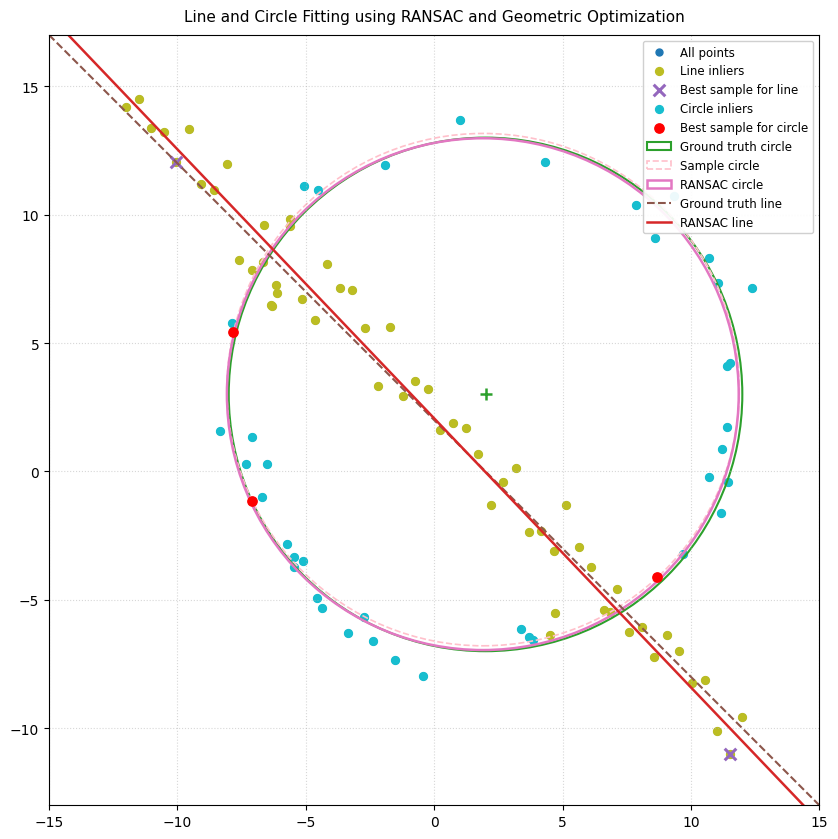

In [ ]:
# (c) Combined Comprehensive Visualization (Matching Figure 1)
fig, ax = plt.subplots(figsize=(8.5, 8.5))

# 1. All Points
ax.scatter(X[:, 0], X[:, 1], color='#1f77b4', s=25, label='All points')

# 2. Line Inliers
ax.scatter(X[best_line_inliers, 0], X[best_line_inliers, 1], color='#bcbd22', s=32, label='Line inliers')

# 3. Best Sample for Line (2 points)
ax.scatter(X[sample_line_idx, 0], X[sample_line_idx, 1], color='#9467bd', marker='x', s=70, linewidths=2.2, label='Best sample for line')

# 4. Circle Inliers
ax.scatter(X[circ_inliers, 0], X[circ_inliers, 1], color='#17becf', s=32, label='Circle inliers')

# 5. Best Sample for Circle (3 points)
ax.scatter(X[sample_circ_idx, 0], X[sample_circ_idx, 1], color='red', s=45, zorder=5, label='Best sample for circle')

# 6. Ground Truth Circle
circle_gt_patch = plt.Circle((x0_gt, y0_gt), r_gt, color='#2ca02c', fill=False, linewidth=1.5, label='Ground truth circle')
ax.add_patch(circle_gt_patch)
ax.plot(x0_gt, y0_gt, '+', color='#2ca02c', markersize=8, markeredgewidth=1.8)

# 7. RANSAC Circle: Sample Estimate (dashed pink) and Refined Fit (solid magenta)
circle_sample_patch = plt.Circle((sample_circ_model[0], sample_circ_model[1]), sample_circ_model[2], color='pink', linestyle='--', fill=False, linewidth=1.2, label='Sample circle')
circle_fit_patch = plt.Circle((best_fit_circle[0], best_fit_circle[1]), best_fit_circle[2], color='#e377c2', fill=False, linewidth=1.8, label='RANSAC circle')
ax.add_patch(circle_sample_patch)
ax.add_patch(circle_fit_patch)

# 8. Ground Truth Line
x_range = np.array([-15, 15])
y_gt_line = m_gt * x_range + b_gt
ax.plot(x_range, y_gt_line, color='#8c564b', linestyle='--', linewidth=1.5, label='Ground truth line')

# 9. RANSAC Line (TLS Refined)
a_fit, b_fit, d_fit = best_fit_line
y_ransac_line = (d_fit - a_fit * x_range) / b_fit
ax.plot(x_range, y_ransac_line, color='#d62728', linewidth=1.8, label='RANSAC line')

ax.set_xlim(-15, 15)
ax.set_ylim(-13, 17)
ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper right', fontsize=8.5, framealpha=0.92)
ax.set_title("Line and Circle Fitting using RANSAC and Geometric Optimization", fontsize=11, pad=10)
plt.tight_layout()
plt.show()


\noindent\textbf{2.4 (d) Discussion: What Happens if We Fit the Circle First?}

\vspace{0.15cm}
A fundamental architectural question in sequential multi-model fitting is the order of model extraction. Reversing the sequence to fit the circle first causes severe geometric failure due to the following reasons:

\begin{enumerate}
    \item \textbf{Secant Line Contamination (False Consensus Inflation):}
    The straight line cuts directly through the circle as a secant line. Points distributed along this line segment inside the circle fall within the radial error tolerance envelope $\tau_{\text{circ}} = 1.50$. Consequently, when fitting the circle first, RANSAC absorbs approximately $11$ collinear line points into the circular consensus set (inflating inliers to $61$).
    
    \item \textbf{Distortion of Estimated Circle Geometry:}
    The contaminated linear points act as leverage points that pull the circumcenter towards the secant chord and distort the estimated radius away from the true parameters.
    
    \item \textbf{Remnant Fragmentation (Destruction of the Line):}
    When the contaminated circle consensus is subtracted from $X$, the middle portion of the line is excised. The remnant point set no longer forms a continuous linear structure, but two disconnected segments with missing centers, severely degrading subsequent line RANSAC.
    
    \item \textbf{Robustness of the Line-First Strategy:}
    In stark contrast, a straight line can intersect a circle in at most \textbf{two points}. Therefore, a candidate line can capture at most $2$ circular points (under noise, at most $\sim 8$ points near the entry and exit points). It can never overfit or consume the circular structure. The consensus threshold $T_{\text{line}} = 35$ guarantees that the line model cannot be formed by circle points. Once the line is removed, the remaining circle points remain fully coherent and intact.
\end{enumerate}


\vspace{0.5cm}
\noindent\textbf{\color{uomaccent}\Large 3. Planar Homography and Image Warping}

\vspace{0.2cm}
\noindent\textbf{3.1 Planar Homography Formulation & Direct Linear Transformation}

\vspace{0.15cm}
A planar homography is a projective transformation mapping homogeneous coordinates $\mathbf{x} = [x, y, 1]^T$ on one planar surface to $\mathbf{x}' = [x', y', 1]^T$ on another planar surface:
\begin{equation}
\mathbf{x}' \sim \mathbf{H} \mathbf{x} \implies \begin{bmatrix} x' \\ y' \\ 1 \end{bmatrix} \sim \begin{bmatrix} h_{11} & h_{12} & h_{13} \\ h_{21} & h_{22} & h_{23} \\ h_{31} & h_{32} & h_{33} \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}
\end{equation}

\noindent\textbf{Degrees of Freedom:}
The matrix $\mathbf{H}$ has 9 entries, but because coordinates are projective (scale invariant), multiplying $\mathbf{H}$ by a non-zero scalar $\lambda \ne 0$ preserves the mapped coordinates: $\lambda \mathbf{H} \sim \mathbf{H}$. Thus, $\mathbf{H}$ possesses \textbf{8 degrees of freedom}.

\noindent\textbf{Direct Linear Transformation (DLT):}
In inhomogeneous coordinates:
\begin{equation}
x' = \frac{h_{11}x + h_{12}y + h_{13}}{h_{31}x + h_{32}y + h_{33}}, \qquad y' = \frac{h_{21}x + h_{22}y + h_{23}}{h_{31}x + h_{32}y + h_{33}}
\end{equation}
Multiplying across gives two linearly independent homogeneous constraints per point correspondence:
\begin{equation}
\begin{bmatrix}
x & y & 1 & 0 & 0 & 0 & -x'x & -x'y & -x' \\
0 & 0 & 0 & x & y & 1 & -y'x & -y'y & -y'
\end{bmatrix}
\begin{bmatrix} h_{11} \\ h_{12} \\ \vdots \\ h_{33} \end{bmatrix} = \mathbf{0}
\end{equation}
With $n = 4$ coplanar point correspondences (where no three points are collinear), we obtain an $8 \times 9$ matrix $\mathbf{A}$. The singular vector corresponding to the zero singular value provides the unique homography solution $\mathbf{H}$ up to scale, computed via \texttt{cv2.getPerspectiveTransform}.

\noindent\textbf{Inverse Warping and Surface Blending:}
Forward mapping causes holes/discretization gaps in the target canvas. We therefore apply \textbf{inverse (backward) mapping} with bilinear interpolation via \texttt{cv2.warpPerspective}: for every target pixel $(x', y')$, the corresponding source coordinate is sampled via $\mathbf{x} = \mathbf{H}^{-1}\mathbf{x}'$.

To replicate Figure 2 of the assignment, the warped overlay is blended onto the target architectural facade using \textbf{additive blending}:
\begin{equation}
\mathbf{I}_{\text{blend}} = \mathbf{I}_{\text{target}} + 0.5\,\mathbf{I}_{\text{warped}}
\end{equation}
This semi-transparent formulation preserves the underlying stone masonry, window mullions, and architectural shadows. For graphical emblems with alpha channels, alpha-compositing is applied:
\begin{equation}
\mathbf{I}_{\text{blend}} = (1 - \alpha \cdot a)\,\mathbf{I}_{\text{target}} + (\alpha \cdot a)\,\mathbf{I}_{\text{warped}}
\end{equation}


In [ ]:
# Task 3: Superimposition Function via Planar Homography
def superimpose_image(target_path, overlay_path, dst_pts, blend_mode='additive', alpha=0.5):
    target = cv2.imread(target_path)
    overlay = cv2.imread(overlay_path, cv2.IMREAD_UNCHANGED)
    
    if target is None:
        raise FileNotFoundError(f"Could not load target image: {target_path}")
    if overlay is None:
        raise FileNotFoundError(f"Could not load overlay image: {overlay_path}")
        
    h_ov, w_ov = overlay.shape[:2]
    src_pts = np.float32([
        [0, 0],
        [w_ov - 1, 0],
        [w_ov - 1, h_ov - 1],
        [0, h_ov - 1]
    ])
    
    # 1. Compute 3x3 planar homography matrix H
    H = cv2.getPerspectiveTransform(src_pts, dst_pts.astype(np.float32))
    
    # 2. Warp overlay onto target image perspective
    h_t, w_t = target.shape[:2]
    warped = cv2.warpPerspective(overlay, H, (w_t, h_t))
    
    # 3. Create binary polygon mask for the planar region
    mask = np.zeros((h_t, w_t), dtype=np.uint8)
    cv2.fillConvexPoly(mask, dst_pts.astype(np.int32), 255)
    
    # 4. Blend warped overlay onto target architectural surface
    result = target.copy()
    if blend_mode == 'additive':
        # Replicates Figure 2: target + 0.5 * warped
        result[mask > 0] = cv2.add(result[mask > 0], (warped[mask > 0, :3] * alpha).astype(np.uint8))
    elif blend_mode == 'alpha':
        if overlay.ndim == 3 and overlay.shape[2] == 4:
            a = (warped[:, :, 3].astype(float) / 255.0)[:, :, None]
            bgr = warped[:, :, :3].astype(float)
            res_float = result.astype(float) * (1.0 - alpha * a) + bgr * (alpha * a)
            result = np.clip(res_float, 0, 255).astype(np.uint8)
        else:
            result[mask > 0] = cv2.addWeighted(result[mask > 0], 1.0 - alpha, warped[mask > 0, :3], alpha, 0)
            
    return result, H


Computed Homography Matrix H (UK Flag -> Wadham Facade):
[[  0.2894  -0.0189 147.    ]
 [  0.0983   0.2999 208.    ]
 [  0.0002  -0.       1.    ]]


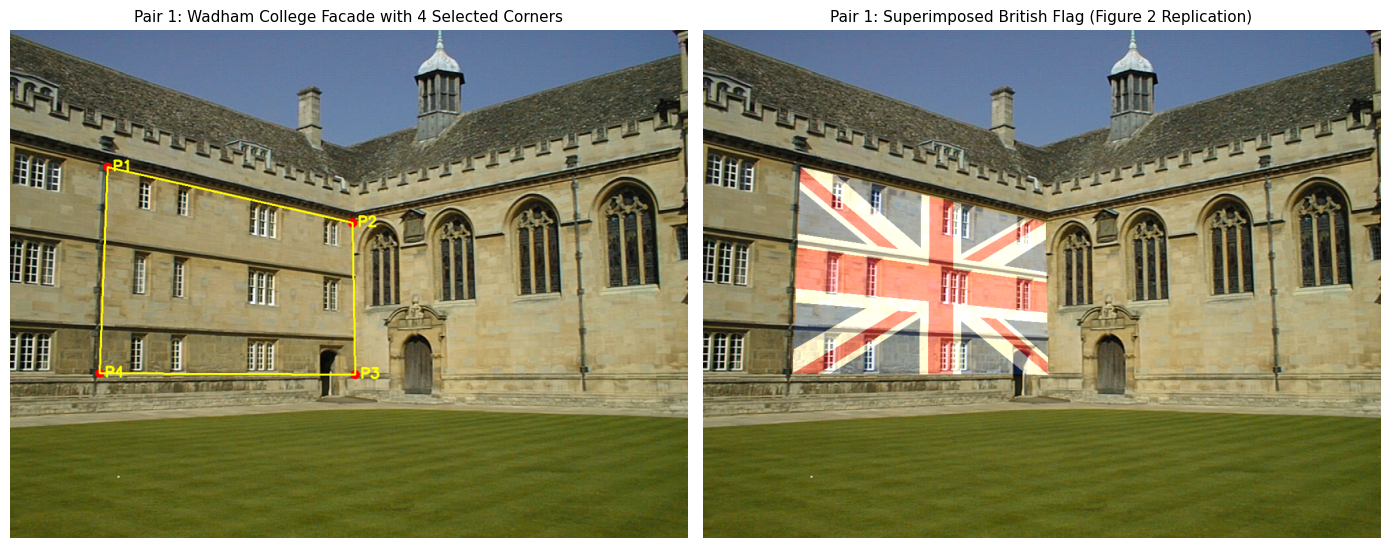

In [ ]:
# 3.2 Image Pair 1: Wadham College and British Flag (Replication of Figure 2)
# Selected 4 coplanar points on the receding quadrangle facade
pts_wadham = np.float32([
    [147, 208],  # P1: Top-Left
    [517, 292],  # P2: Top-Right
    [521, 521],  # P3: Bottom-Right
    [135, 519]   # P4: Bottom-Left
])

res_wadham, H_wadham = superimpose_image(
    'src/wadham.jpg', 'src/flag.png', pts_wadham, blend_mode='additive', alpha=0.5
)

# Create annotated image showing the 4 clicked points
orig_wadham = cv2.imread('src/wadham.jpg')
for i, pt in enumerate(pts_wadham):
    cv2.circle(orig_wadham, tuple(pt.astype(int)), 7, (0, 0, 255), -1)
    cv2.putText(orig_wadham, f"P{i+1}", (int(pt[0]) + 8, int(pt[1]) + 5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2, cv2.LINE_AA)
cv2.polylines(orig_wadham, [pts_wadham.astype(np.int32)], True, (0, 255, 255), 2)

print("Computed Homography Matrix H (UK Flag -> Wadham Facade):")
print(np.array2string(H_wadham, precision=4, suppress_small=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(orig_wadham, cv2.COLOR_BGR2RGB))
axes[0].set_title("Pair 1: Wadham College Facade with 4 Selected Corners", fontsize=11)
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(res_wadham, cv2.COLOR_BGR2RGB))
axes[1].set_title("Pair 1: Superimposed British Flag (Figure 2 Replication)", fontsize=11)
axes[1].axis('off')
plt.tight_layout()
plt.show()


\noindent\textbf{3.2 Non-Technical Rationale and Visual Observation for Pair 1}

\vspace{0.15cm}
\begin{itemize}
    \item \textbf{Selected 4 Points:} $P_1(147, 208)$, $P_2(517, 292)$, $P_3(521, 521)$, $P_4(135, 519)$ along the architectural cornices and vertical masonry lines of the front quadrangle.
    \item \textbf{Non-Technical Rationale:} Celebrating English collegiate heritage by projecting the British Union Jack onto the historic 17th-century Jacobean quadrangle of Wadham College, Oxford.
    \item \textbf{Visual Observation:} Additive blending preserves the underlying stone window frames, mullions, and masonry shadow details, giving the visual impression of a high-power laser architectural projection onto the stone facade.
\end{itemize}


Computed Homography Matrix H (UoM Emblem -> Facade):
[[  0.0615   0.     382.    ]
 [ -0.3761   0.7901 346.    ]
 [ -0.0004   0.       1.    ]]


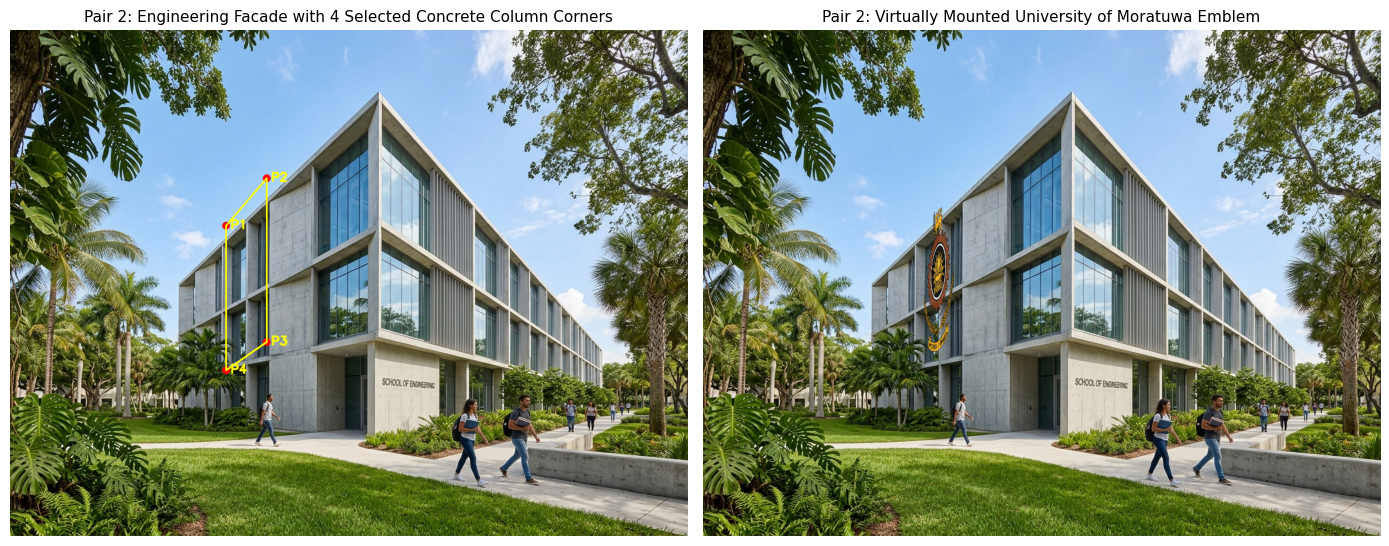

In [ ]:
# 3.3 Image Pair 2: Engineering Faculty Architectural Facade and UoM Coat of Arms
# Selected 4 coplanar points on the vertical concrete structural bays
pts_uom = np.float32([
    [382, 346],  # P1: Top-Left
    [454, 262],  # P2: Top-Right
    [454, 552],  # P3: Bottom-Right
    [382, 602]   # P4: Bottom-Left
])

res_uom, H_uom = superimpose_image(
    'src/uom_engineering_facade.jpg', 'doc/Images/University_of_Moratuwa_logo.png',
    pts_uom, blend_mode='alpha', alpha=0.90
)

# Create annotated image showing the 4 clicked points
orig_uom = cv2.imread('src/uom_engineering_facade.jpg')
for i, pt in enumerate(pts_uom):
    cv2.circle(orig_uom, tuple(pt.astype(int)), 7, (0, 0, 255), -1)
    cv2.putText(orig_uom, f"P{i+1}", (int(pt[0]) + 8, int(pt[1]) + 5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2, cv2.LINE_AA)
cv2.polylines(orig_uom, [pts_uom.astype(np.int32)], True, (0, 255, 255), 2)

print("Computed Homography Matrix H (UoM Emblem -> Facade):")
print(np.array2string(H_uom, precision=4, suppress_small=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(orig_uom, cv2.COLOR_BGR2RGB))
axes[0].set_title("Pair 2: Engineering Facade with 4 Selected Concrete Column Corners", fontsize=11)
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(res_uom, cv2.COLOR_BGR2RGB))
axes[1].set_title("Pair 2: Virtually Mounted University of Moratuwa Emblem", fontsize=11)
axes[1].axis('off')
plt.tight_layout()
plt.show()


\noindent\textbf{3.3 Non-Technical Rationale and Visual Observation for Pair 2}

\vspace{0.15cm}
\begin{itemize}
    \item \textbf{Selected 4 Points:} $P_1(382, 346)$, $P_2(454, 262)$, $P_3(454, 552)$, $P_4(382, 602)$ bounded by the structural reinforced concrete pillars and horizontal floor beams of the building.
    \item \textbf{Non-Technical Rationale:} Institutional campus branding and identity. The official crest of the University of Moratuwa is digitally mounted onto the structural concrete facade of the Faculty of Engineering, simulating an architectural crest installation.
    \item \textbf{Visual Observation:} The warped emblem naturally follows the building's perspective foreshortening towards the vanishing point. The vertical crest edges align flush with the structural columns, appearing as an authentic physical plaque mounted to the exterior wall.
\end{itemize}
